### Model Rollout Analysis
In this notebook, we analyze model rollout performance of both models (Pi05 and XR-1) across epochs:  

**Comparison between training epochs:**
- 1st epoch
- 2nd epoch
- ...
- all trained on the same dataset, same starting point etc. 

In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
from IPython.display import display

In [3]:
Pi05_df = pd.read_csv('raw_data/Pi05_eval_epochs.csv', delimiter=";")
XR1_df = pd.read_csv('raw_data/XR1_eval_epochs.csv', delimiter=";")

In [4]:
Pi05_df.head()

,Run Name,Date,Attempt,Pin no.,Epoch,Success_Overall,Grab_Success,Handover_Success,Put_Down_Success,Time(s),Comment
0,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:44,1.0,1.0,1.0,True,True,True,True,20.0,NaN
1,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:44,2.0,2.0,1.0,False,True,False,NaN,18.0,NaN
2,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:45,1.0,1.0,1.0,False,True,False,NaN,48.0,NaN
3,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:45,2.0,2.0,1.0,False,True,False,NaN,49.0,NaN
4,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:45,5.0,2.0,1.0,True,True,True,True,36.0,NaN


In [5]:
XR1_df.head()

,Run Name,Date,Attempt,Pin no.,Epoch,Success_Overall,Grab_Success,Handover_Success,Put_Down_Success,Time(s),Comment
0,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,18/11/2026 12:09,1,1,1,True,True,True,True,18,NaN
1,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,18/11/2026 12:09,2,2,1,True,True,True,True,16,NaN
2,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,18/11/2026 12:09,3,3,1,True,True,True,True,17,NaN
3,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,18/11/2026 12:09,4,4,1,True,True,True,True,17,NaN
4,xr1full_ANTON_X_BOCCONI_clean4_20261106_1827/s...,18/11/2026 12:09,5,5,1,True,True,True,True,14,NaN


In [6]:
print(f'No. of Pi05 obersvations: {len(Pi05_df)}')
print(f'No. of XR1 obersvations: {len(XR1_df)}')

No. of Pi05 obersvations: 206
No. of XR1 obersvations: 344


In [7]:
bool_cols = ["Success_Overall", "Grab_Success", "Handover_Success", "Put_Down_Success"]
boolean_values = {"True": True, "False": False}

for df in (Pi05_df, XR1_df):
    df.dropna(how="all", inplace=True)
    for col in bool_cols:
        df[col] = (df[col].astype("string").str.strip()
                   .map(boolean_values).astype("boolean"))
    df["Epoch"] = pd.to_numeric(df["Epoch"], errors="coerce")
    df["Time(s)"] = pd.to_numeric(df["Time(s)"], errors="coerce")

/var/folders/hf/wpyjr1gx2l5cb_tyndpj5wk00000gn/T/ipykernel_94047/2653169381.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(how="all", inplace=True)
/var/folders/hf/wpyjr1gx2l5cb_tyndpj5wk00000gn/T/ipykernel_94047/2653169381.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(how="all", inplace=True)


## Fine-tuning epoch figures

In [8]:
# Reuse the robustness notebook's paper styling and export convention.
set_matplotlib_formats("svg")
plt.rcParams.update({
    "font.family": "DejaVu Serif", "font.size": 13,
    "axes.labelsize": 15, "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "axes.linewidth": 1,
    "xtick.major.width": 1, "ytick.major.width": 1,
    "xtick.major.size": 4, "ytick.major.size": 4,
    "pdf.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 300,
})
figure_dir = Path("..") / "Results" / "epoch_evaluation"
figure_dir.mkdir(parents=True, exist_ok=True)
model_order = ["Pi0.5", "XR1"]
model_lines = {
    "Pi0.5": dict(color="#242424", marker="o", linestyle="-"),
    "XR1": dict(color="#666666", marker="s", linestyle="--"),
}
segment_colors = ["#242424", "#969696", "#e3e3e3"]
step_columns = {
    "Grab_Success": "Grab", "Handover_Success": "Handover",
    "Put_Down_Success": "Put down",
}
epoch_ticks = [1, 2, 3, 4]

def style_axes(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, color="#dddddd", linewidth=0.45)
    ax.tick_params(direction="out")

# Build one common result dataframe for both models
results = pd.concat(
    [Pi05_df.assign(Model="Pi0.5"), XR1_df.assign(Model="XR1")],
    ignore_index=True,
)

# First observed failed stage wins; later missing stages are not additional failures
results["First failed stage"] = pd.NA
for column, stage in step_columns.items():
    first = results["First failed stage"].isna() & results[column].eq(False).fillna(False)
    results.loc[first, "First failed stage"] = stage

results.head()

,Run Name,Date,Attempt,Pin no.,Epoch,Success_Overall,Grab_Success,Handover_Success,Put_Down_Success,Time(s),Comment,Model,First failed stage
0,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:44,1.0,1.0,1.0,True,True,True,True,20.0,NaN,Pi0.5,<NA>
1,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:44,2.0,2.0,1.0,False,True,False,<NA>,18.0,NaN,Pi0.5,Handover
2,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:45,1.0,1.0,1.0,False,True,False,<NA>,48.0,NaN,Pi0.5,Handover
3,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:45,2.0,2.0,1.0,False,True,False,<NA>,49.0,NaN,Pi0.5,Handover
4,pi05rel_full_ANTON_X_BOCCONI_clean4/004331,18/11/2026 09:45,5.0,2.0,1.0,True,True,True,True,36.0,NaN,Pi0.5,<NA>


### Per-epoch evaluation summary

- Success rate uses overall outcomes as its denominator and successful outcomes as nominator. 
- Completion time uses successful attempts only (i.e. time of failed attempts doesn't count). 
- Failure-stage counts use the first recorded failed stage. 

In [9]:
summary_rows = []

for (model, epoch), group in results.groupby(["Model", "Epoch"], sort=True):
    success = group["Success_Overall"].eq(True)
    failure = group["Success_Overall"].eq(False)
    stages = group.loc[failure, "First failed stage"].value_counts()
    successful_times = group.loc[success.fillna(False), "Time(s)"]
    successful_times = successful_times[successful_times.gt(0) & np.isfinite(successful_times)]
    summary_rows.append({
        "Model": model, "Epoch": int(epoch), "Valid attempts": len(group),
        "Successes": int(success.sum()), "Success rate (%)": 100 * success.mean(),
        "Mean completion time (s)": successful_times.mean(),
        "Timed successes": len(successful_times),
        "Failures": int(failure.sum()),
        "Grab failures": int(stages.get("Grab", 0)),
        "Handover failures": int(stages.get("Handover", 0)),
        "Put-down failures": int(stages.get("Put down", 0)),
    })
summary = pd.DataFrame(summary_rows).sort_values(["Model", "Epoch"]).reset_index(drop=True)

display(summary.round({"Success rate (%)": 2, "Mean completion time (s)": 2}))

,Model,Epoch,Valid attempts,Successes,Success rate (%),Mean completion time (s),Timed successes,Failures,Grab failures,Handover failures,Put-down failures
0,Pi0.5,1,44,11,25.00,24.64,11,33,2,27,4
1,Pi0.5,2,50,37,74.00,24.16,37,13,2,11,0
2,Pi0.5,3,61,47,77.05,23.74,47,14,4,8,2
3,Pi0.5,4,50,45,90.00,24.20,45,5,1,1,3
4,XR1,1,57,47,82.46,16.94,47,10,0,1,9
5,XR1,2,49,48,97.96,17.54,48,1,1,0,0
6,XR1,4,238,231,97.06,20.77,231,7,6,0,1


### Overall task success by epoch

- Each datapoint equals the fraction of successful attempts. 
- XR1 has no epoch-3 evaluation since the robot gripper broke mid recording and cannot be fixed short-term. Its dashed line connects the observed epochs 2 and 4 without an epoch-3 marker. 

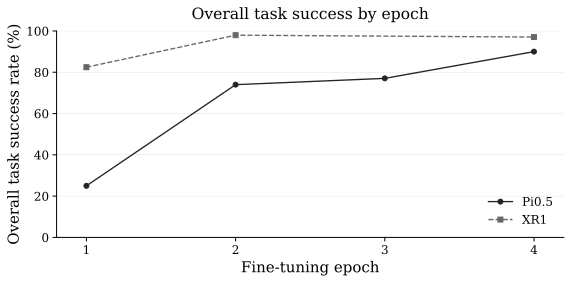

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for model in model_order:
    series = summary.loc[summary["Model"].eq(model)].set_index("Epoch")
    values = series["Success rate (%)"].reindex(epoch_ticks)
    observed = values.dropna()
    ax.plot(observed.index, observed.to_numpy(), label=model, markersize=5, linewidth=1.35, **model_lines[model])
ax.set(xlabel="Fine-tuning epoch", ylabel="Overall task success rate (%)",
       xticks=epoch_ticks, xlim=(0.8, 4.2), ylim=(0, 100))
ax.set_yticks(range(0, 101, 20))
ax.legend(frameon=False, loc="lower right")
style_axes(ax)
ax.set_title("Overall task success by epoch", pad=12)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "success_rate_by_epoch.png", bbox_inches="tight")
plt.show()

### Successful completion time by epoch

Means include only successful tasks with a finite, positive completion time.

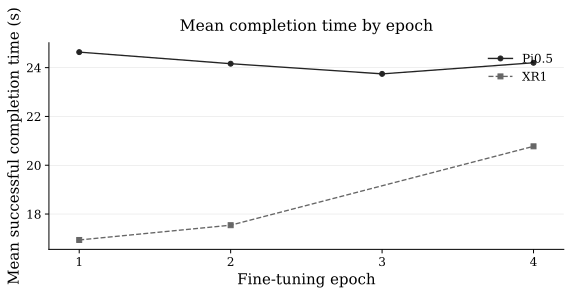

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for model in model_order:
    series = summary.loc[summary["Model"].eq(model)].set_index("Epoch")
    values = series["Mean completion time (s)"].reindex(epoch_ticks)
    observed = values.dropna()
    ax.plot(observed.index, observed.to_numpy(), label=model, markersize=5, linewidth=1.35,
            **model_lines[model])
ax.set(xlabel="Fine-tuning epoch", ylabel="Mean successful completion time (s)",
       xticks=epoch_ticks, xlim=(0.8, 4.2))
ax.legend(frameon=False, loc="upper right")
style_axes(ax)
ax.set_title("Mean completion time by epoch", pad=12)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "completion_time_by_epoch.png", bbox_inches="tight")
plt.show()

### First failure stage by epoch

Each bar shows the percentage distributions of grab, handover, and put-down failures among all failed attempts in that epoch. 

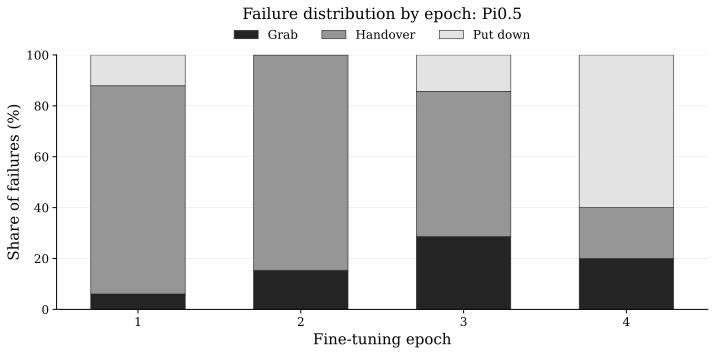

In [12]:
model_summary = summary.loc[summary["Model"].eq("Pi0.5")].set_index("Epoch")
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(model_summary))
failures = model_summary["Failures"].to_numpy()
for stage, column, color in zip(
        ("Grab", "Handover", "Put down"),
        ("Grab failures", "Handover failures", "Put-down failures"),
        segment_colors):
    count = model_summary[column].to_numpy()
    share = np.divide(100 * count, failures,
                      out=np.zeros(len(count), dtype=float), where=failures > 0)
    ax.bar(model_summary.index, share, bottom=bottom, width=0.58,
           label=stage, color=color, edgecolor="#242424", linewidth=0.6)
    bottom += share
for epoch, n_failed in zip(model_summary.index, failures):
    if n_failed == 0:
        ax.text(epoch, 4, "0 failures", ha="center", va="bottom", fontsize=10)
ax.set(xlabel="Fine-tuning epoch", ylabel="Share of failures (%)",
       xticks=epoch_ticks, xlim=(0.5, 4.5), ylim=(0, 100))
ax.set_yticks(range(0, 101, 20))
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3)
style_axes(ax)
ax.set_title("Failure distribution by epoch: Pi0.5", pad=36)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "failure_distribution_pi05.png", bbox_inches="tight")
plt.show()

#### XR1 failure distribution

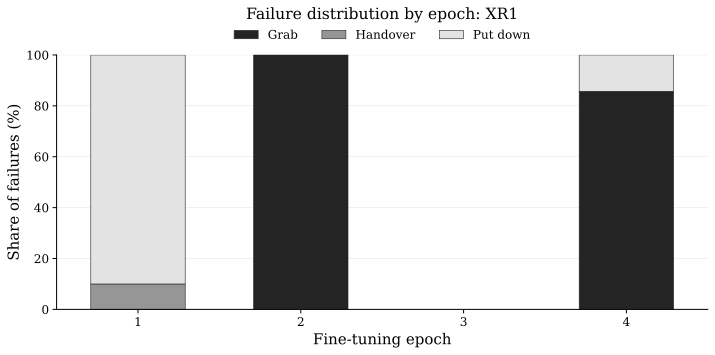

In [13]:
model_summary = summary.loc[summary["Model"].eq("XR1")].set_index("Epoch")
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(model_summary))
failures = model_summary["Failures"].to_numpy()
for stage, column, color in zip(
        ("Grab", "Handover", "Put down"),
        ("Grab failures", "Handover failures", "Put-down failures"),
        segment_colors):
    count = model_summary[column].to_numpy()
    share = np.divide(100 * count, failures,
                      out=np.zeros(len(count), dtype=float), where=failures > 0)
    ax.bar(model_summary.index, share, bottom=bottom, width=0.58,
           label=stage, color=color, edgecolor="#242424", linewidth=0.6)
    bottom += share
for epoch, n_failed in zip(model_summary.index, failures):
    if n_failed == 0:
        ax.text(epoch, 4, "0 failures", ha="center", va="bottom", fontsize=10)
ax.set(xlabel="Fine-tuning epoch", ylabel="Share of failures (%)",
       xticks=epoch_ticks, xlim=(0.5, 4.5), ylim=(0, 100))
ax.set_yticks(range(0, 101, 20))
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3)
style_axes(ax)
ax.set_title("Failure distribution by epoch: XR1", pad=36)
fig.tight_layout(pad=0.7)
fig.savefig(figure_dir / "failure_distribution_xr1.png", bbox_inches="tight")
plt.show()

### Evaluation success alongside training loss

- Evaluation success and training loss are compared per epoch. 
- The loss logs provide a fractional `epoch` value for each logged optimization step. 
- For each model, the chart uses the mean loss from steps within epoch 1, 2, 3, or 4 and the real-life evaluation success rate labeled with that same epoch. 
- Pi0.5 and XR1's training objectives have different scales, so their loss values are not comparable one-to-one. 
- XR1 has no epoch-3 evaluation.

In [14]:
loss_specs = {
    "Pi0.5": ("Pi05_trainloss.csv", "loss", "Pi0.5 training loss"),
    "XR1": ("xr1_trainloss.csv", "loss_total", "XR1 total training loss"),
}
loss_summary = {}
for model, (filename, loss_column, _) in loss_specs.items():
    log = pd.read_csv(Path("raw_data") / filename)
    for column in ("epoch", loss_column):
        log[column] = pd.to_numeric(log[column], errors="coerce")
    log = log.dropna(subset=["epoch", loss_column])
    log = log.loc[log["epoch"].gt(0)].copy()
    log["Epoch"] = np.ceil(log["epoch"]).astype(int)
    loss_summary[model] = log.groupby("Epoch")[loss_column].mean().reindex(epoch_ticks)

display(pd.DataFrame(loss_summary, index=epoch_ticks).rename_axis("Epoch").round(4))

,Pi0.5,XR1
Epoch,,
1,0.0218,1.0222
2,0.0085,0.6666
3,0.0058,0.5209
4,0.0042,0.4251


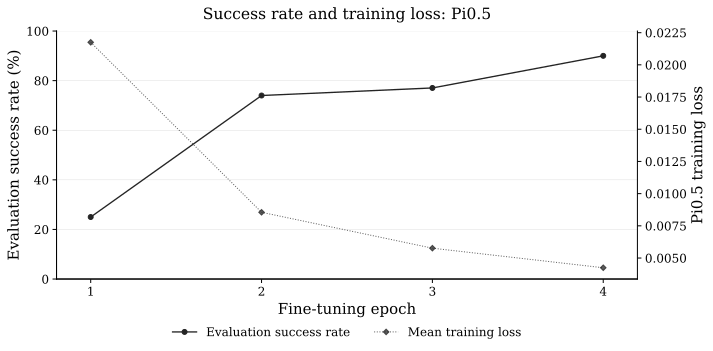

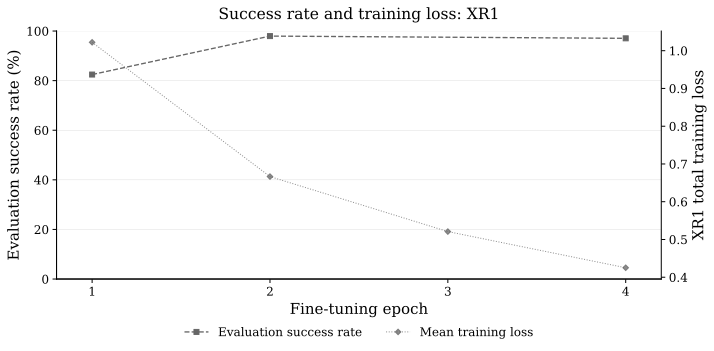

In [15]:
def plot_success_and_loss(model, filename):
    series = summary.loc[summary["Model"].eq(model)].set_index("Epoch")
    success = series["Success rate (%)"].reindex(epoch_ticks).dropna()
    fig, ax = plt.subplots(figsize=(10, 5))
    success_line, = ax.plot(success.index, success, label="Evaluation success rate",
                            markersize=5, linewidth=1.35, **model_lines[model])
    ax.set(xlabel="Fine-tuning epoch", ylabel="Evaluation success rate (%)",
           xticks=epoch_ticks, xlim=(0.8, 4.2), ylim=(0, 100))
    ax.set_yticks(range(0, 101, 20))
    style_axes(ax)
    ax_loss = ax.twinx()
    # Lighter, thinner dashed loss curve keeps the two metrics distinct.
    loss_line, = ax_loss.plot(epoch_ticks, loss_summary[model], label="Mean training loss",
                              color=model_lines[model]["color"], linestyle=":",
                              marker="D", markersize=4, linewidth=1.0, alpha=0.75)
    ax_loss.set_ylabel(loss_specs[model][2])
    ax_loss.spines["top"].set_visible(False)
    ax_loss.tick_params(direction="out")
    ax.legend([success_line, loss_line], ["Evaluation success rate", "Mean training loss"],
              frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
    ax.set_title(f"Success rate and training loss: {model}", pad=12)
    fig.tight_layout(pad=0.7)
    fig.savefig(figure_dir / filename, bbox_inches="tight")
    plt.show()

plot_success_and_loss("Pi0.5", "success_rate_train_loss_pi05.png")
plot_success_and_loss("XR1", "success_rate_train_loss_xr1.png")

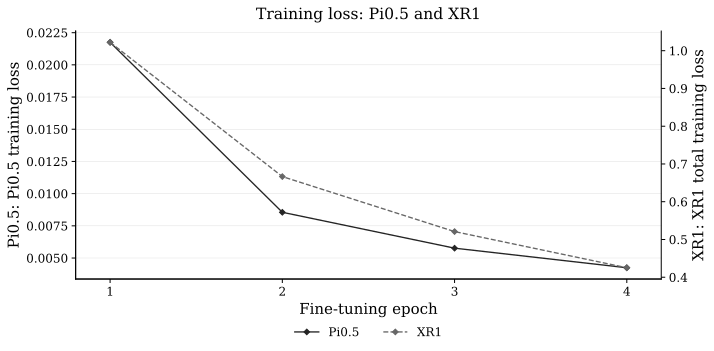

In [16]:
def plot_training_losses(filename):
    fig, ax_pi = plt.subplots(figsize=(10, 5))
    ax_xr = ax_pi.twinx()

    pi_line, = ax_pi.plot(
        epoch_ticks, loss_summary["Pi0.5"],
        label="Pi0.5",
        color=model_lines["Pi0.5"]["color"],
        marker="D", markersize=4, linewidth=1.35
    )

    xr_line, = ax_xr.plot(
        epoch_ticks, loss_summary["XR1"],
        label="XR1",
        color=model_lines["XR1"]["color"],
        marker="D", markersize=4, linewidth=1.35,
        linestyle="--"
    )

    ax_pi.set(
        xlabel="Fine-tuning epoch",
        ylabel=f"Pi0.5: {loss_specs['Pi0.5'][2]}",
        xticks=epoch_ticks,
        xlim=(0.8, 4.2)
    )
    ax_xr.set_ylabel(f"XR1: {loss_specs['XR1'][2]}")

    style_axes(ax_pi)
    ax_xr.spines["top"].set_visible(False)
    ax_xr.tick_params(direction="out")

    ax_pi.legend(
        [pi_line, xr_line], ["Pi0.5", "XR1"],
        frameon=False, loc="upper center",
        bbox_to_anchor=(0.5, -0.15), ncol=2
    )

    ax_pi.set_title("Training loss: Pi0.5 and XR1", pad=12)
    fig.tight_layout(pad=0.7)
    fig.savefig(figure_dir / filename, bbox_inches="tight")
    plt.show()


plot_training_losses("training_loss_comparison.png")